# TP3 — LSTM, GRU et sentiment

**Cours :** Réseaux de neurones récurrents (RNN) — 20 h — Master 1 SDIA
**Enseignante :** Dr. Noulapeu Ngaffo Armielle — ENSPD, Université de Douala
**Durée conseillée :** 2 h · **Barème :** 10 points

---

## Objectifs

- Comparer RNN, GRU et LSTM sur une même tâche.
- Mesurer l'apport du bidirectionnel.
- Comprendre le rôle de la taille du corpus.

## Travail demandé

1. Répondre aux 3 questions de la section « À vous ».
2. Rendre le notebook exécuté.

## Mode d'emploi

- Exécuter dans l'ordre ; tout tourne sur CPU (moins de 2 minutes).
- Les cellules **« À vous »** sont évaluées ; graines fixées.

In [1]:
%matplotlib inline
import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
torch.manual_seed(4112); np.random.seed(4112)
torch.set_num_threads(2)

## 1. Un corpus étiqueté, assez grand pour apprendre

Corpus **généré par gabarits** : `sujet + verbe + complément`, avec des lexiques positifs et négatifs. Ce n'est pas un jeu de référence — c'est un support contrôlé pour comparer des architectures.

In [2]:
rng = np.random.default_rng(4112)
sujets = ["le film", "cette histoire", "le scenario", "la mise en scene",
          "les acteurs", "ce realisateur", "la musique", "le rythme"]
pos = ["excellent", "captivant", "remarquable", "superbe",
       "brillant", "emouvant", "reussi"]
neg = ["mauvais", "ennuyeux", "confus", "rate", "plat",
       "interminable", "pauvre"]

def simple(label):
    s = rng.choice(sujets); a = rng.choice(pos if label else neg)
    return f"{s} est {a}"

def contraste(label):
    # l'etiquette vient de la PREMIERE proposition : il faut s'en souvenir
    s1, s2 = rng.choice(sujets, 2, replace=False)
    a1 = rng.choice(pos if label else neg)
    a2 = rng.choice(neg if label else pos)
    return f"{s1} est {a1} meme si {s2} est {a2}"

def longue(label):
    # l'indice est noye au milieu d'une longue phrase : il faut s'en souvenir
    remplissage = ["vraiment", "assez", "plutot", "franchement", "un peu",
                   "tres", "globalement", "au final", "selon moi", "sans doute",
                   "encore", "toujours"]
    mots = [rng.choice(remplissage) for _ in range(14)]
    cle = rng.choice(pos if label else neg)
    i = int(rng.integers(0, len(mots)))
    mots.insert(i, cle)
    return "le film " + " ".join(mots)

def negation(label):
    s = rng.choice(sujets)
    a = rng.choice(neg) if label else rng.choice(pos)
    return f"{s} n est pas {a}"

phrases, labels = [], []
for _ in range(700):
    lab = int(rng.random() < .5)
    kind = rng.choice(["simple", "contraste", "negation", "longue"],
                      p=[.25, .20, .15, .40])
    phrases.append({"simple": simple, "contraste": contraste,
                    "negation": negation, "longue": longue}[kind](lab))
    labels.append(lab)
print("phrases :", len(phrases), "| positifs :", sum(labels))
print("simple   :", simple(1))
print("contraste:", contraste(1), " <- etiquette = positive (1re proposition)")
print("negation :", negation(1))

phrases : 700 | positifs : 360
simple   : le film est brillant
contraste: cette histoire est reussi meme si les acteurs est mauvais  <- etiquette = positive (1re proposition)
negation : cette histoire n est pas plat


In [3]:
from sklearn.model_selection import train_test_split
mots = sorted({m for p in phrases for m in p.split()})
vocab = {"<pad>": 0}
for m in mots:
    vocab[m] = len(vocab)
L = max(len(p.split()) for p in phrases)

def encode(p):
    ids = [vocab[m] for m in p.split()]
    return ids + [0] * (L - len(ids))

X = torch.tensor([encode(p) for p in phrases])
y = torch.tensor(labels, dtype=torch.long)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, random_state=4112, stratify=y)
print("vocabulaire :", len(vocab), "| longueur :", L)
print("train :", tuple(Xtr.shape), "| test :", tuple(Xte.shape))

vocabulaire : 51 | longueur : 27
train : (525, 27) | test : (175, 27)


## 2. Une fonction d'entraînement commune

In [4]:
class Classifieur(nn.Module):
    def __init__(self, cellule="rnn", H=48, bidir=False):
        super().__init__()
        self.emb = nn.Embedding(len(vocab), 32, padding_idx=0)
        cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cellule]
        self.rnn = cls(32, H, batch_first=True, bidirectional=bidir)
        self.drop = nn.Dropout(0.2)
        self.out = nn.Linear(H * (2 if bidir else 1), 2)
    def forward(self, x):
        v = self.emb(x)
        s, _ = self.rnn(v)
        return self.out(self.drop(s[:, -1, :]))

def entraine(modele, epoques=40, lr=5e-3):
    opt = torch.optim.Adam(modele.parameters(), lr=lr)
    pf = nn.CrossEntropyLoss()
    for ep in range(epoques):
        modele.train(); opt.zero_grad()
        perte = pf(modele(Xtr), ytr)
        perte.backward()
        torch.nn.utils.clip_grad_norm_(modele.parameters(), 5.0)
        opt.step()
    modele.eval()
    with torch.no_grad():
        acc = (modele(Xte).argmax(1) == yte).float().mean().item()
    return round(float(perte), 4), round(acc, 4)

In [5]:
resultats = {}
for nom, kw in [("RNN", dict(cellule="rnn")),
                ("GRU", dict(cellule="gru")),
                ("LSTM", dict(cellule="lstm")),
                ("LSTM bidirectionnel", dict(cellule="lstm", bidir=True))]:
    perte, acc = entraine(Classifieur(**kw))
    resultats[nom] = acc
    print(f"{nom:<22} perte={perte:.4f}   exactitude test={acc:.1%}")

C:\Users\HP\AppData\Local\Temp\ipykernel_12424\2170929654.py:26: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  return round(float(perte), 4), round(acc, 4)


RNN                    perte=0.1649   exactitude test=82.9%


GRU                    perte=0.0908   exactitude test=87.4%


LSTM                   perte=0.1730   exactitude test=83.4%


LSTM bidirectionnel    perte=0.3090   exactitude test=81.7%


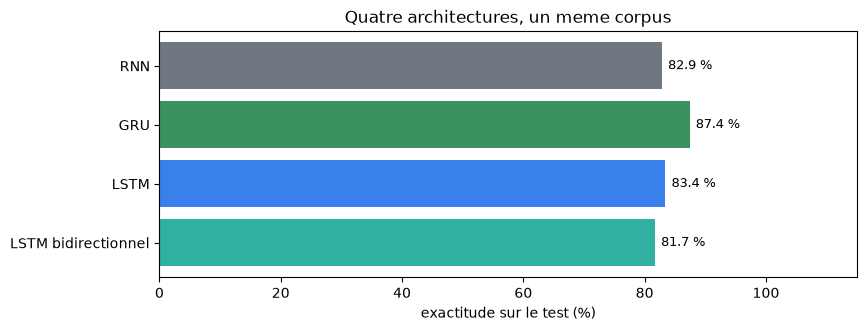

In [6]:
noms = list(resultats)
vals = [resultats[n] * 100 for n in noms]
plt.figure(figsize=(9, 3.2))
b = plt.barh(noms[::-1], vals[::-1],
             color=["#5B6470", "#1E8449", "#1F6FEB", "#12A594"][::-1], alpha=.88)
for bb, v in zip(b, vals[::-1]):
    plt.text(v + 1, bb.get_y() + bb.get_height()/2, f"{v:.1f} %", va="center", fontsize=9)
plt.xlim(0, 115); plt.xlabel("exactitude sur le test (%)")
plt.title("Quatre architectures, un meme corpus")
plt.show()

## 3. À vous

**1.** Les écarts entre architectures sont ici modestes : proposez deux raisons (taille du corpus, longueur des dépendances, nombre d'époques).

**2.** Réduisez le corpus à 40 phrases : les classements tiennent-ils ? Concluez sur la taille d'échantillon.

**3.** Remplacez le dernier état `s[:, -1, :]` par une moyenne masquée : est-ce plus stable ?

In [7]:
# ---- A VOUS ----
# 1)
# 2)
# 3)

## 4. Synthèse

| Ce qu'il faut retenir | |
|---|---|
| corpus suffisant | sinon les écarts sont du bruit |
| GRU > RNN ici | moins de paramètres, convergence plus sûre |
| LSTM ≈ RNN ici | la mémoire longue ne paie que si la tâche l'exige |
| bidirectionnel | **non avantagé** sur ce corpus : la théorie ne remplace pas la mesure |

**Leçon de méthode :** classer des architectures sans mesurer est une faute. Les écarts dépendent du corpus, de la longueur des dépendances et du budget d'entraînement.